# 01 · Del preentrenado al alineado: RLHF, DPO y GRPO

Este es un módulo de Neural Networks 1002. Supone el [módulo 10 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/) (el GPT construido desde cero, predicción del siguiente token, muestreo) y el [módulo 04 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/04-aprendizaje-por-refuerzo/) (aprendizaje por refuerzo: gradiente de política, líneas base, PPO, manipulación de la recompensa).

Un **modelo base** solo predice el siguiente token. Imita su texto de entrenamiento, errores incluidos. Convertirlo en algo que *hace la tarea* se llama **post-entrenamiento**, y este notebook ejecuta toda la cadena a escala de juguete en la CPU de un portátil:

1. un GPT diminuto se preentrena con texto en el que las respuestas de una tarea de ordenación son correctas solo una cuarta parte de las veces (como el texto ruidoso de la web);
2. **ajuste fino supervisado (SFT)** con unas pocas demostraciones correctas;
3. un **modelo de recompensa** (RM) entrenado con preferencias por pares con la pérdida de Bradley-Terry, y medido contra la verdad de referencia;
4. **ajuste fino por gradiente de política** con una penalización por alejarse del modelo SFT: REINFORCE (REward Increment = Nonnegative Factor x Offset Reinforcement x Characteristic Eligibility) y una actualización recortada tipo PPO (optimización de política proximal), midiendo la exactitud real, la recompensa y la KL (divergencia de Kullback-Leibler);
5. **sobreoptimización de la recompensa**: empujar demasiado la recompensa sustituta hace que la calidad real se hunda (ley de Goodhart), con el coeficiente KL como mando;
6. **DPO** (optimización directa de preferencias) con los mismos pares de preferencias;
7. **GRPO** (optimización de política relativa a grupos) con una recompensa verificable, sin modelo de recompensa y sin red de valor;
8. límites, en qué se diferencia el juguete de los sistemas de producción, y una nota sobre alineación, seguridad y evaluación.

**Contenido**
1. La tarea de juguete y el modelo base
2. SFT: aprender de demostraciones
3. Un modelo de recompensa a partir de preferencias
4. Gradiente de política contra el modelo de recompensa, con penalización KL
5. Sobreoptimización de la recompensa (ley de Goodhart)
6. DPO: preferencias sin modelo de recompensa
7. GRPO: recompensas verificables, sin red de valor
8. Comparación, límites, alineación y evaluación
9. Ideas clave, Ejercicios, Referencias

**Se apoya en**

| Módulo | Qué aportó | Uso aquí |
|---|---|---|
| 1001 módulo 10, LLM (GPT desde cero) | el GPT solo decodificador, pérdida del siguiente token, muestreo | la clase del modelo, el preentrenamiento y el muestreo de la sección 1 |
| 1001 módulo 04, aprendizaje por refuerzo | gradiente de política, líneas base, recorte de PPO, manipulación de la recompensa | secciones 4, 5 y 7 |
| 1001 módulo 03, entrenar bien | AdamW, recorte de gradientes, tasas de aprendizaje | todos los bucles de entrenamiento |

**Siguiente:** [módulo 14 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/14-agentes-y-orquestacion/) (agentes y orquestación, donde las mismas ideas de recompensa guían sistemas que usan herramientas; véase también el [curso de sistemas RAG](https://rag-systems.academy.forwardforecasting.eu/es/05-agentes-con-langgraph/) para agentes con LangGraph) y [módulo 15](https://neural-networks-1002.academy.forwardforecasting.eu/es/15-modelos-generalistas-y-agi/) (modelos generalistas y el camino hacia la AGI (inteligencia artificial general), donde el entrenamiento con recompensas verificables es parte de cómo se construyen los modelos de razonamiento).

En qué se diferencia el juguete de los sistemas reales: nuestro modelo tiene unos 100 mil pesos y las respuestas son de 6 tokens; los modelos de producción tienen miles de millones de pesos, respuestas de cientos de tokens, modelos de recompensa de tamaño parecido y anotadores humanos o de IA (inteligencia artificial). Los mecanismos son los mismos, las cifras no son comparables.

Tiempo: unos 2 minutos en un entorno limpio de 2 CPU (medido; llegó a 15 minutos, 939 s, en un portátil compartido y ocupado); las ejecuciones de sobreoptimización de la sección 5 son cerca de un tercio.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/01_rlhf_y_alineacion.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 2 minutos, con un pico de memoria de menos de 1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import copy, math, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

T_START = time.time()
random.seed(0); np.random.seed(0); torch.manual_seed(0)
torch.set_num_threads(2)

## 1. La tarea de juguete y el modelo base

Necesitamos una tarea con una **verdad comprobable**, para medir cada afirmación sobre la calidad en lugar de solo argumentarla. Usamos **ordenar cinco dígitos**: al prompt `s41846=` debe seguirle `14468` y un salto de línea. Un token es un carácter, y el modelo es el GPT del módulo 10 de Neural Networks 1001, más pequeño (2 capas, ancho 64, unos 100 mil pesos) para que todo corra en minutos.

La decisión clave de diseño: el texto de preentrenamiento contiene respuestas que son **correctas solo el 25 % de las veces**. El otro 75 % son errores verosímiles: un dígito cambiado, dos vecinos intercambiados o una mezcla completa. Un modelo base entrenado así aprende la *distribución de respuestas del texto*, incluidas las erróneas, igual que un modelo entrenado con texto de la web aprende a imitar lo que haya. Dos maneras de leer el modelo se comportan de forma muy distinta:

* la **decodificación voraz** (siempre el token más probable) devuelve la moda de la distribución;
* el **muestreo a temperatura 1** devuelve un sorteo de la distribución, así que su exactitud es la fracción de masa de probabilidad que está en respuestas correctas.

El post-entrenamiento actúa sobre todo en la segunda cantidad: mueve masa de probabilidad hacia las buenas respuestas. Todas las exactitudes de abajo son **muestreadas** y de **coincidencia exacta** (los seis tokens correctos), medidas sobre prompts fijos no vistos salvo que se indique otra cosa. Con 600 a 1000 prompts, una exactitud medida tiene un ruido de unos 2 puntos arriba o abajo.

In [2]:
N = 5                                           # dígitos por prompt
chars = list("0123456789s=\n")
stoi = {c: i for i, c in enumerate(chars)}      # los caracteres de dígito tienen id 0..9, igual a su valor
itos = {i: c for c, i in stoi.items()}
V = len(chars)
enc = lambda s: [stoi[c] for c in s]
dec = lambda ids: "".join(itos[i] for i in ids)
LL = N + 2 + N + 1                              # longitud de línea: 's' + 5 dígitos + '=' + 5 dígitos + salto = 13 tokens

def corrupt(sorted_digits):
    # un error verosímil: cambiar un dígito, intercambiar dos vecinos o mezclar todo
    a = list(sorted_digits); k = random.random()
    if k < 0.4:
        a[random.randrange(N)] = random.randint(0, 9)
    elif k < 0.7:
        i = random.randrange(N - 1); a[i], a[i + 1] = a[i + 1], a[i]
    else:
        random.shuffle(a)
    return a

def make_line(p_good):
    # una línea de entrenamiento: prompt, '=', respuesta. La respuesta es correcta con probabilidad p_good.
    ds = [random.randint(0, 9) for _ in range(N)]
    ans = sorted(ds) if random.random() < p_good else corrupt(sorted(ds))
    return "s" + "".join(map(str, ds)) + "=" + "".join(map(str, ans)) + "\n"

def make_prompts(n):
    ds = torch.randint(0, 10, (n, N))
    prompts = torch.cat([torch.full((n, 1), stoi["s"]), ds, torch.full((n, 1), stoi["="])], 1)
    return ds, prompts

def truth(ds, seq):
    # verdad de referencia: coincidencia exacta con los dígitos ordenados más el salto, y fracción de caracteres correctos
    ans = seq[:, N + 2:]
    gold = torch.cat([ds.sort(1).values, torch.full((len(ds), 1), stoi["\n"])], 1)
    return (ans == gold).all(1).float(), (ans == gold).float().mean(1)

print("ejemplos de líneas del corpus (la respuesta tras '=' a veces es errónea, como el texto ruidoso de la web):")
for _ in range(6): print("  ", repr(make_line(0.25)))

ejemplos de líneas del corpus (la respuesta tras '=' a veces es errónea, como el texto ruidoso de la web):
   's66048=80466\n'
   's82421=12248\n'
   's24115=11645\n'
   's93877=87789\n'
   's16097=51679\n'
   's39332=32339\n'


In [3]:
class Attn(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.h = h; s.qkv = nn.Linear(d, 3 * d); s.proj = nn.Linear(d, d)
    def forward(s, x):
        B, T, D = x.shape; q, k, v = s.qkv(x).split(D, 2)
        q, k, v = (t.view(B, T, s.h, D // s.h).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)      # máscara causal: cada token solo ve el pasado
        return s.proj(y.transpose(1, 2).reshape(B, T, D))

class Block(nn.Module):
    def __init__(s, d, h):
        super().__init__(); s.l1 = nn.LayerNorm(d); s.a = Attn(d, h); s.l2 = nn.LayerNorm(d)
        s.m = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(s, x):
        x = x + s.a(s.l1(x)); return x + s.m(s.l2(x))

class GPT(nn.Module):
    # el GPT del módulo 10 de Neural Networks 1001, sin caché KV y más pequeño: 2 capas, ancho 64
    def __init__(s, V, block=16, d=64, L=2, h=4):
        super().__init__(); s.te = nn.Embedding(V, d); s.pe = nn.Embedding(block, d)
        s.blocks = nn.ModuleList(Block(d, h) for _ in range(L)); s.lnf = nn.LayerNorm(d)
        s.head = nn.Linear(d, V, bias=False); s.head.weight = s.te.weight; s.apply(s._i)
    def _i(s, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
    def hidden(s, idx):
        x = s.te(idx) + s.pe(torch.arange(idx.shape[1]))
        for b in s.blocks: x = b(x)
        return s.lnf(x)
    def forward(s, idx): return s.head(s.hidden(idx))

def lm_loss(m, batch, answer_only=False):
    x, y = batch[:, :-1], batch[:, 1:]
    lo = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1), reduction="none").view(y.shape)
    return (lo[:, N + 1:] if answer_only else lo).mean()

@torch.no_grad()
def sample(m, prompts, greedy=False):
    # escribe los 6 tokens de la respuesta (5 dígitos y el salto), uno a uno
    idx = prompts
    for _ in range(N + 1):
        lg = m(idx)[:, -1]
        nx = lg.argmax(-1, keepdim=True) if greedy else torch.multinomial(lg.softmax(-1), 1)
        idx = torch.cat([idx, nx], 1)
    return idx

torch.manual_seed(1); EV_DS, EV_P = make_prompts(1000)      # un conjunto de evaluación fijo de 1000 prompts
def evaluate(m, greedy=False):
    seq = sample(m, EV_P, greedy); return truth(EV_DS, seq)[0].mean().item()

torch.manual_seed(0); random.seed(0)
model = GPT(V)
print(f"GPT con {sum(p.numel() for p in model.parameters()):,} parámetros")

GPT con 101,952 parámetros


## 2. Preentrenamiento y SFT

Primero el modelo base: pérdida del siguiente token sobre 20.000 líneas, 500 pasos de AdamW. Después **SFT** (ajuste fino supervisado): seguimos entrenando con la misma pérdida, pero solo con **200 demostraciones siempre correctas** y con la pérdida solo sobre los tokens de la respuesta. SFT es "imitar buenos ejemplos", la primera etapa de toda cadena de asistentes. Congelamos luego una copia del modelo SFT como **política de referencia** $\pi_{\text{ref}}$ (pi, la probabilidad que el modelo de referencia da a una secuencia), que todas las etapas siguientes usan para medir cuánto se ha movido el nuevo modelo.

In [4]:
random.seed(0); torch.manual_seed(0)
data = torch.tensor(enc("".join(make_line(0.25) for _ in range(20000)))).view(-1, LL)
STEPS = 500
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=0.1, betas=(0.9, 0.95))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=STEPS, pct_start=0.05)
t0 = time.time()
for step in range(STEPS):
    loss = lm_loss(model, data[torch.randint(len(data), (64,))])
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
base = model
acc_base_s, acc_base_g = evaluate(base), evaluate(base, greedy=True)
print(f"pre-training: {STEPS} steps, {time.time() - t0:.0f} s, final loss {loss.item():.3f}")
print(f"base model, sampling at temperature 1: {acc_base_s:.1%} of the answers are exactly right")
print(f"base model, greedy decoding         : {acc_base_g:.1%}")
ds, p = make_prompts(6); sq = sample(base, p)
for d, q in zip(ds, sq): print("  ", "".join(map(str, d.tolist())), "->", dec(q[N + 2:].tolist()).strip())

pre-training: 500 steps, 33 s, final loss 1.326
base model, sampling at temperature 1: 36.7% of the answers are exactly right
base model, greedy decoding         : 99.5%
   73539 -> 33579
   57894 -> 45789
   57557 -> 55577
   65577 -> 56577
   03548 -> 03458
   26971 -> 16979


In [5]:
# Ajuste fino supervisado (SFT): 200 demostraciones siempre correctas, pérdida solo sobre los tokens de la respuesta
random.seed(5); torch.manual_seed(5)
sft_data = torch.tensor(enc("".join(make_line(1.0) for _ in range(200)))).view(-1, LL)
sm = copy.deepcopy(base)
o = torch.optim.AdamW(sm.parameters(), lr=2e-4)
for step in range(40):
    loss = lm_loss(sm, sft_data[torch.randint(len(sft_data), (32,))], answer_only=True)
    o.zero_grad(); loss.backward(); o.step()
acc_sft_s, acc_sft_g = evaluate(sm), evaluate(sm, greedy=True)
print(f"after SFT (40 steps on 200 demonstrations): sampled {acc_sft_s:.1%}, greedy {acc_sft_g:.1%}")

ref = copy.deepcopy(sm).eval()          # política de referencia congelada para toda penalización KL de abajo
for q in ref.parameters(): q.requires_grad_(False)

after SFT (40 steps on 200 demonstrations): sampled 76.1%, greedy 99.6%


**Lectura.** La decodificación voraz del modelo base ya acierta el 99,5 % de las veces: la respuesta más probable es la correcta, porque la respuesta correcta es el patrón individual más frecuente. Pero el muestreo da solo un 36,7 % de respuestas exactas, porque la masa se reparte entre muchos errores verosímiles. Esta brecha es la situación de un modelo base real: el comportamiento correcto existe dentro, pero no de forma fiable. 40 pasos de SFT con 200 demostraciones correctas suben la exactitud muestreada al 76,1 % mientras la voraz se queda en 99,6 %. SFT es barato y eficaz, y deja un 24 % de respuestas muestreadas erróneas, que es el margen en el que trabajan las siguientes etapas. (Los conjuntos SFT reales son mucho más variados y la mejora también se refiere a formato y estilo, no solo a exactitud.)

## 3. Un modelo de recompensa a partir de preferencias

Las demostraciones dicen al modelo qué escribir. Las **preferencias** dicen cuál de dos salidas es mejor, algo más fácil de dar para las personas que una respuesta perfecta. Un **modelo de recompensa** $r_\phi(x, y)$ (una puntuación escalar para el prompt $x$ y la respuesta $y$; $\phi$ son sus pesos) se entrena para que la respuesta preferida $y_w$ ("ganadora") puntúe más que la rechazada $y_l$ ("perdedora") con el modelo de **Bradley-Terry**: la probabilidad de que $y_w$ gane es $\sigma(r_\phi(x,y_w) - r_\phi(x,y_l))$, donde $\sigma$ es la función logística. La pérdida es

$$\mathcal{L}(\phi) = -\,\mathbb{E}\,\log \sigma\big(r_\phi(x,y_w) - r_\phi(x,y_l)\big).$$

Solo se identifican las **diferencias** de puntuación dentro de un mismo prompt, un punto que importa en la sección 4.

Nuestros datos de preferencia se generan con una **regla**: una respuesta correcta gana a una errónea. Esto permite medir el modelo de recompensa contra la verdad, algo imposible con etiquetas humanas. Para hacerlo realista, las respuestas rechazadas son muestras del modelo, la mitad sustituidas por **casi aciertos** (una respuesta ordenada con un dígito cambiado, que parece correcta pero no lo es), y **se invierte el 10 % de las etiquetas** para imitar el ruido de los anotadores. El modelo de recompensa es la red SFT con una cabeza escalar sobre el estado oculto medio de las posiciones de la respuesta.

In [6]:
def near_miss(ds):
    # un negativo difícil: respuesta ordenada con un dígito cambiado por otro valor (PARECE ordenada pero es errónea)
    a = ds.sort(1).values.clone(); n = len(a)
    pos = torch.randint(0, N, (n,)); a[torch.arange(n), pos] = (a[torch.arange(n), pos] + torch.randint(1, 10, (n,))) % 10
    return a.sort(1).values

def make_pairs(n, seed, flip=0.0, hard=0.0, policy=None):
    # n prompts -> pares (elegida, rechazada). La regla (verdad de referencia) dice: una respuesta correcta gana a una errónea.
    # Las respuestas erróneas se muestrean del modelo (una fracción `hard` son casi aciertos); `flip` es ruido de etiquetas.
    torch.manual_seed(seed); ds, p = make_prompts(n)
    a = sample(policy or base, p)
    nl = torch.full((n, 1), stoi["\n"])
    gold = torch.cat([p, ds.sort(1).values, nl], 1)
    nm = torch.cat([p, near_miss(ds), nl], 1)
    a = torch.where((torch.rand(n) < hard)[:, None], nm, a)
    keep = truth(ds, a)[0] == 0                  # conserva solo los prompts donde la respuesta muestreada es errónea
    w, l = gold[keep], a[keep]
    f = torch.rand(len(w)) < flip
    return torch.where(f[:, None], l, w), torch.where(f[:, None], w, l)

class RM(nn.Module):
    # modelo de recompensa: la red SFT con una cabeza escalar sobre el estado oculto medio de las posiciones de la respuesta
    def __init__(s, backbone):
        super().__init__(); s.g = copy.deepcopy(backbone); s.v = nn.Linear(64, 1)
    def forward(s, seq): return s.v(s.g.hidden(seq)[:, N + 1:].mean(1)).squeeze(-1)

W, L = make_pairs(12000, 10, flip=0.10, hard=0.5)          # pares de entrenamiento, 10 % de etiquetas invertidas
teW, teL = make_pairs(3000, 11, hard=0.5)                  # pares no vistos con etiquetas limpias
onW, onL = make_pairs(6000, 12, policy=sm)                 # pares no vistos cuyas respuestas erróneas vienen de la política SFT
print(f"{len(W)} training pairs; example chosen/rejected: {dec(W[0][N + 2:].tolist()).strip()!r} > {dec(L[0][N + 2:].tolist()).strip()!r} "
      f"(prompt {dec(W[0][1:N + 1].tolist())})")

torch.manual_seed(0)
rm = RM(sm); o = torch.optim.AdamW(rm.parameters(), lr=5e-4, weight_decay=0.01)
t0 = time.time(); rm_losses = []
for step in range(300):
    i = torch.randint(len(W), (32,))
    loss = -F.logsigmoid(rm(W[i]) - rm(L[i])).mean()          # pérdida de Bradley-Terry
    o.zero_grad(); loss.backward(); o.step(); rm_losses.append(loss.item())
with torch.no_grad():
    acc_rm_mixed = (rm(teW) > rm(teL)).float().mean().item()
    acc_rm_on = (rm(onW) > rm(onL)).float().mean().item()
    ds_, p_ = make_prompts(2000); S = sample(sm, p_); r = rm(S); MU, SD = r.mean().item(), r.std().item()
print(f"reward model trained in {time.time() - t0:.0f} s")
print(f"held-out pair accuracy (clean labels), mixed wrong answers: {acc_rm_mixed:.1%}")
print(f"held-out pair accuracy, wrong answers sampled from the SFT policy: {acc_rm_on:.1%}")

9869 training pairs; example chosen/rejected: '12557' > '81572' (prompt 57215)


reward model trained in 26 s
held-out pair accuracy (clean labels), mixed wrong answers: 95.1%
held-out pair accuracy, wrong answers sampled from the SFT policy: 94.4%


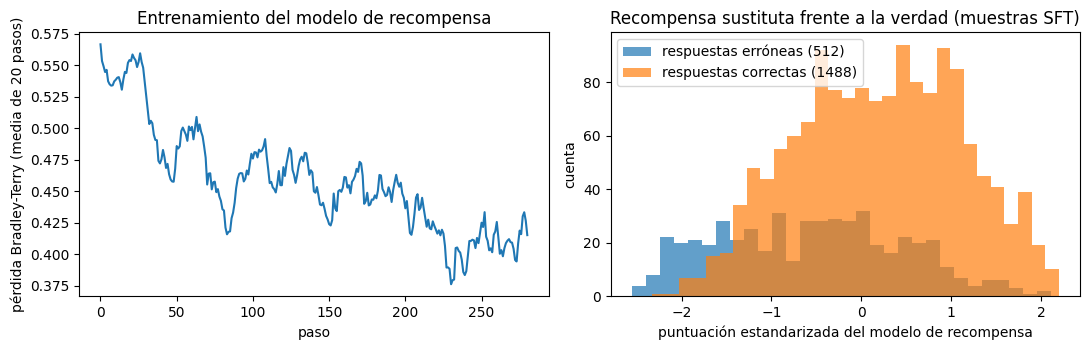

mean standardised score: correct 0.20, wrong -0.57


In [7]:
# ¿Sigue la recompensa sustituta a la verdad? Puntúa 2000 muestras SFT con el modelo de recompensa, separadas por acierto exacto.
with torch.no_grad():
    ex_S = truth(ds_, S)[0]; z = (rm(S) - MU) / SD
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.convolve(rm_losses, np.ones(20) / 20, "valid")); ax[0].set_xlabel("paso"); ax[0].set_ylabel("pérdida Bradley-Terry (media de 20 pasos)")
ax[0].set_title("Entrenamiento del modelo de recompensa")
ax[1].hist(z[ex_S == 0].numpy(), bins=30, alpha=.7, label=f"respuestas erróneas ({int((ex_S == 0).sum())})")
ax[1].hist(z[ex_S == 1].numpy(), bins=30, alpha=.7, label=f"respuestas correctas ({int((ex_S == 1).sum())})")
ax[1].set_xlabel("puntuación estandarizada del modelo de recompensa"); ax[1].set_ylabel("cuenta"); ax[1].set_title("Recompensa sustituta frente a la verdad (muestras SFT)"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"mean standardised score: correct {z[ex_S == 1].mean():.2f}, wrong {z[ex_S == 0].mean():.2f}")

**Lectura.** En pares no vistos con etiquetas limpias el modelo de recompensa prefiere la respuesta correcta el 95,1 % de las veces (94,4 % cuando las respuestas erróneas vienen de la propia política SFT), pese a un 10 % de etiquetas ruidosas en el entrenamiento. Es un buen resultado para un modelo de 100 mil pesos, pero no perfecto, y el histograma muestra qué significa "no perfecto": las distribuciones de puntuación de las respuestas correctas (media +0,20) y de las erróneas (media -0,57) se solapan mucho, en parte porque la puntuación también depende del prompt (solo se entrenaron diferencias dentro del prompt). Un sustituto que acierta el 95 % de las veces en su propia distribución de entrenamiento es un *sustituto*, y las dos secciones siguientes lo usan y lo abusan.

## 4. Gradiente de política contra el modelo de recompensa, con penalización KL

Ahora mejoramos la política $\pi_\theta$ (probabilidad de cada token dado el texto anterior; $\theta$ son sus pesos, inicializados con el modelo SFT). Para una respuesta muestreada $y$ la recompensa es

$$R(x,y) = r_\phi(x,y) - \beta\,\log\frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)},$$

donde el segundo término es una estimación por muestra de la **divergencia KL** entre la política nueva y la de referencia, y $\beta$ (beta) es el coeficiente KL. La penalización mantiene la política cerca del modelo que el modelo de recompensa aprendió a juzgar. El gradiente es el del módulo 04 de Neural Networks 1001: subir la log-probabilidad de las respuestas con recompensa por encima de la línea base.

Dos detalles prácticos. (a) Muestreamos $K=4$ respuestas por prompt y usamos como **línea base** la recompensa media de las otras respuestas al mismo prompt (línea base de dejar uno fuera, [Ahmadian et al. 2024](https://arxiv.org/abs/2402.14740)). Probamos primero la media del lote como línea base y falló en nuestras ejecuciones: las puntuaciones del modelo de recompensa llevan un desplazamiento propio de cada prompt (la pérdida nunca lo fija) que ahoga la señal. (b) **REINFORCE** da un paso de gradiente por lote; la actualización **tipo PPO** reutiliza el lote durante dos épocas y recorta la razón de probabilidades a $[0{,}8, 1{,}2]$, como en el módulo 04. Aquí no hay red de valor, la línea base de grupo la sustituye.

In [8]:
def tok_logp(m, seq):
    # log-probabilidad de cada uno de los 6 tokens de la respuesta bajo el modelo m (forzado del maestro sobre la secuencia muestreada)
    lp = F.log_softmax(m(seq[:, :-1]), -1).gather(-1, seq[:, 1:, None]).squeeze(-1)
    return lp[:, N + 1:]

EP, EDS = EV_P[:600], EV_DS[:600]
@torch.no_grad()
def probe(pol):
    # medido en 600 prompts fijos: exactitud real, recompensa sustituta (estandarizada) y KL a la referencia (suma sobre los tokens de la respuesta)
    seq = sample(pol, EP); ex = truth(EDS, seq)[0]
    kl = (tok_logp(pol, seq) - tok_logp(ref, seq)).sum(1).mean().item()
    return ex.mean().item(), ((rm(seq) - MU) / SD).mean().item(), kl

K = 4                                            # respuestas muestreadas por prompt
def run_rl(mode, beta, iters, bs=32, lr=3e-4, seed=0, log=10, epochs=2):
    # gradiente de política contra el modelo de recompensa. recompensa = recompensa sustituta - beta * KL(secuencia).
    # línea base = media de las otras respuestas al mismo prompt. modo: 'reinforce' o 'ppo'
    torch.manual_seed(seed); pol = copy.deepcopy(sm); opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0)
    hist = []
    for it in range(iters + 1):
        if it % log == 0: hist.append((it,) + probe(pol))
        if it == iters: break
        _, p = make_prompts(bs); p = p.repeat_interleave(K, 0); seq = sample(pol, p)
        with torch.no_grad():
            lp_old = tok_logp(pol, seq); kl = (lp_old - tok_logp(ref, seq)).sum(1)
            tot = ((rm(seq) - MU) / SD - beta * kl).view(bs, K)
        adv = ((tot - tot.mean(1, keepdim=True)) * K / (K - 1)).view(-1)      # línea base de dejar uno fuera
        for ep in range(1 if mode == "reinforce" else epochs):
            lp = tok_logp(pol, seq)
            if mode == "reinforce":
                loss = -(adv * lp.sum(1)).mean()
            else:                                                             # sustituto recortado de PPO
                ratio = (lp - lp_old).exp(); a = adv[:, None]
                loss = -torch.min(ratio * a, ratio.clamp(0.8, 1.2) * a).sum(1).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
    return pol, np.array(hist)

BETA = 0.1
runs = {}; t0 = time.time()
for mode in ["reinforce", "ppo"]:
    runs[mode] = run_rl(mode, BETA, 100)
    print(f"{mode:9s} beta={BETA}: " + "  ".join(f"it{int(r[0])}: acc {r[1]:.2f}" for r in runs[mode][1][::2]) + f"   ({time.time() - t0:.0f} s)")

reinforce beta=0.1: it0: acc 0.76  it20: acc 0.74  it40: acc 0.82  it60: acc 0.83  it80: acc 0.86  it100: acc 0.84   (45 s)


ppo       beta=0.1: it0: acc 0.76  it20: acc 0.80  it40: acc 0.81  it60: acc 0.83  it80: acc 0.89  it100: acc 0.88   (102 s)


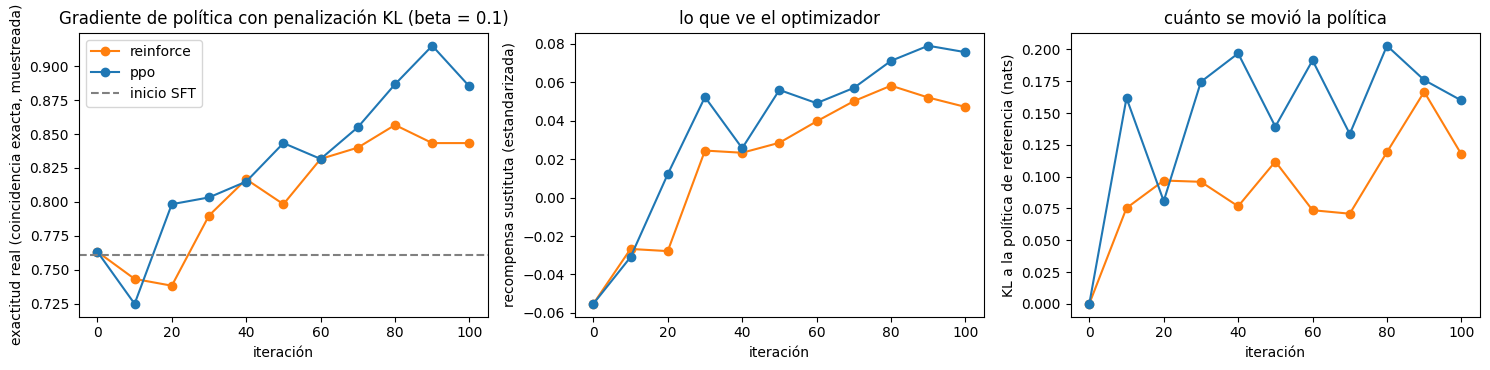

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for mode, c in [("reinforce", "tab:orange"), ("ppo", "tab:blue")]:
    h = runs[mode][1]
    for a, col, lab in zip(ax, [1, 2, 3], ["exactitud real (coincidencia exacta, muestreada)", "recompensa sustituta (estandarizada)", "KL a la política de referencia (nats)"]):
        a.plot(h[:, 0], h[:, col], "o-", color=c, label=mode); a.set_xlabel("iteración"); a.set_ylabel(lab)
ax[0].axhline(acc_sft_s, color="gray", ls="--", label="inicio SFT"); ax[0].legend(); ax[0].set_title(f"Gradiente de política con penalización KL (beta = {BETA})")
ax[1].set_title("lo que ve el optimizador"); ax[2].set_title("cuánto se movió la política")
plt.tight_layout(); plt.show()

**Lectura.** Ambos métodos suben la exactitud muestreada del 76 % a los 80 y pocos con una KL de solo 0,1 a 0,2 nats (un nat es la unidad de información del logaritmo natural), así que la política cambia poco. Al final de la ejecución PPO está en el 88,5 % y REINFORCE en el 84,3 %; con un ruido de unos 2 puntos y una sola semilla, lo leemos como "PPO es al menos igual de bueno y fue por delante la mayor parte de la ejecución", no como un orden demostrado. La recompensa sustituta sube junto con la exactitud real: con un ancla KL suficientemente fuerte el modelo de recompensa es una guía útil. La sección siguiente quita el ancla.

## 5. Sobreoptimización de la recompensa (ley de Goodhart)

Ley de Goodhart: cuando una medida se convierte en objetivo, deja de ser una buena medida. Repetimos la ejecución PPO durante 150 iteraciones con cuatro valores del coeficiente KL $\beta$, y dibujamos la **recompensa sustituta** (lo que ve el optimizador) y la **exactitud real** (lo que nos importa) frente a la distancia recorrida, como en [Gao et al. 2022](https://arxiv.org/abs/2210.10760). El modelo de recompensa no se reentrena nunca, así que cualquier brecha es la política explotando sus errores.

In [10]:
BETAS = [0.0, 0.02, 0.1, 0.5]
over = {}; t0 = time.time()
for b in BETAS:
    over[b] = run_rl("ppo", b, 150, log=10)
    h = over[b][1]
    print(f"beta={b:<4}: final true acc {h[-1, 1]:.2f}, best {h[:, 1].max():.2f}, proxy reward {h[-1, 2]:+.2f}, KL {h[-1, 3]:.2f}   ({time.time() - t0:.0f} s)")

beta=0.0 : final true acc 0.19, best 0.76, proxy reward +0.12, KL 5.18   (77 s)


beta=0.02: final true acc 0.86, best 0.88, proxy reward +0.10, KL 0.46   (167 s)


beta=0.1 : final true acc 0.92, best 0.92, proxy reward +0.09, KL 0.17   (263 s)


beta=0.5 : final true acc 0.90, best 0.91, proxy reward +0.07, KL 0.11   (350 s)


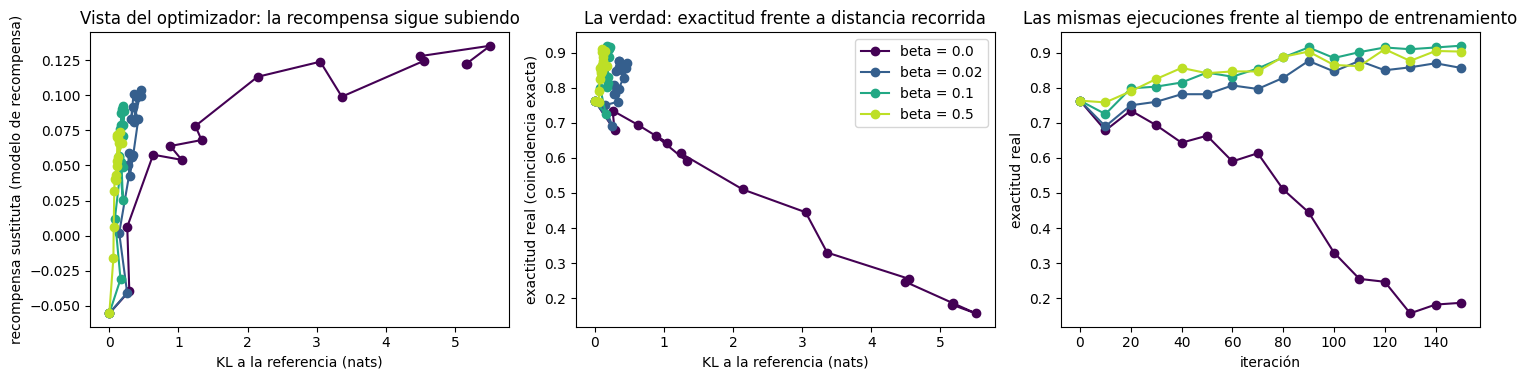

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
cols = plt.cm.viridis(np.linspace(0, .9, len(BETAS)))
for b, c in zip(BETAS, cols):
    h = over[b][1]
    ax[0].plot(h[:, 3], h[:, 2], "o-", color=c, label=f"beta = {b}")
    ax[1].plot(h[:, 3], h[:, 1], "o-", color=c, label=f"beta = {b}")
    ax[2].plot(h[:, 0], h[:, 1], "o-", color=c, label=f"beta = {b}")
ax[0].set_xlabel("KL a la referencia (nats)"); ax[0].set_ylabel("recompensa sustituta (modelo de recompensa)"); ax[0].set_title("Vista del optimizador: la recompensa sigue subiendo")
ax[1].set_xlabel("KL a la referencia (nats)"); ax[1].set_ylabel("exactitud real (coincidencia exacta)"); ax[1].set_title("La verdad: exactitud frente a distancia recorrida"); ax[1].legend()
ax[2].set_xlabel("iteración"); ax[2].set_ylabel("exactitud real"); ax[2].set_title("Las mismas ejecuciones frente al tiempo de entrenamiento")
plt.tight_layout(); plt.show()

In [12]:
# ¿Qué escribe la política sobreoptimizada? (beta = 0, sin ancla a la referencia)
pol0 = over[0.0][0]
ds, p = make_prompts(10); torch.manual_seed(7); sq = sample(pol0, p)
sc = ((rm(sq) - MU) / SD).detach()
print("prompt   correcta política puntuación  exacta")
for d, q, s_ in zip(ds, sq, sc):
    gold = "".join(map(str, sorted(d.tolist())))
    ans = dec(q[N + 2:].tolist()).replace("\n", "|")
    print(f"{''.join(map(str, d.tolist()))}    {gold}   {ans}   {s_:+.2f}        {'sí' if ans[:-1] == gold and ans[-1] == '|' else 'NO'}")

prompt   correcta política puntuación  exacta
41846    14468   14467|   +0.74        NO
85724    24578   24577|   +1.13        NO
91446    14469   14467|   +1.11        NO
29776    26779   26777|   +0.44        NO
33167    13367   13367|   +0.60        sí
51618    11568   11567|   +0.22        NO
14896    14689   14687|   +0.45        NO
00833    00338   00337|   -0.11        NO
30662    02366   02367|   -0.81        NO
18898    18889   18887|   +0.25        NO


**Lectura.** Con $\beta = 0$ la política se mueve mucho (KL 5,2 nats) y la exactitud real cae del 76 % al **19 %**, mientras la recompensa sustituta termina en +0,12, la más alta de las cuatro ejecuciones. Mira las muestras: la política escribe respuestas que parecen ordenadas pero con un dígito mal (para `41846` escribe `14467`, la correcta es `14468`). Encontró lo que el modelo de recompensa no sabe comprobar bien (que los dígitos sean los correctos) y le da lo que le gusta (una serie ascendente), el mismo patrón de casi acierto que pusimos entre los negativos difíciles, pero ahora en una forma que el modelo no aprendió a rechazar. Con $\beta = 0{,}02$ la exactitud termina en el 86 % (KL 0,46), con $\beta = 0{,}1$ en el 92 % (KL 0,17) y con $\beta = 0{,}5$ en el 90 % (KL 0,11). Así que el coeficiente KL es un mando real: demasiado pequeño y la política hace trampa, valores moderados dan el mejor resultado, y uno grande empieza a frenar la política (0,90 frente a 0,92 está dentro del ruido, no afirmamos diferencia). Obsérvese que la recompensa sustituta apenas difiere entre ejecuciones (+0,07 a +0,12) mientras que la exactitud real difiere casi cinco veces: **un sustituto puede parecer bien mientras la verdad se hunde**. Es una semilla por $\beta$; la dirección es grande, el orden exacto entre las tres ejecuciones regularizadas no está establecido. Los sistemas reales lo combaten con modelos de recompensa mayores y mejores, parada temprana con una métrica no vista, presupuestos de KL, conjuntos de modelos de recompensa y, cuando se puede, recompensas verificables (sección 7).

## 6. DPO: preferencias sin modelo de recompensa

La **optimización directa de preferencias** ([Rafailov et al. 2023](https://arxiv.org/abs/2305.18290)) observa que el objetivo con penalización KL tiene un óptimo en forma cerrada, así que la recompensa puede escribirse con la propia política: $r(x,y) = \beta \log \frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \text{const}$. Al sustituirlo en la pérdida de Bradley-Terry sale una pérdida solo sobre la política:

$$\mathcal{L}_{\text{DPO}} = -\,\mathbb{E}\,\log\sigma\Big(\beta\Big[\log\tfrac{\pi_\theta(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)} - \log\tfrac{\pi_\theta(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\Big]\Big).$$

Sin modelo de recompensa, sin muestreo durante el entrenamiento, solo pasos supervisados sobre los **mismos pares de preferencias** (unos 9.900 pares, con el mismo 10 % de etiquetas invertidas). La política hace implícitamente de modelo de recompensa.

In [13]:
def seq_logp(m, seq): return tok_logp(m, seq).sum(1)

def run_dpo(beta, iters, lr=1e-4, bs=64, log=10, seed=0):
    # DPO: pérdida = -log sigmoide( beta * [ (log pi(elegida) - log ref(elegida)) - (log pi(rechazada) - log ref(rechazada)) ] )
    torch.manual_seed(seed); pol = copy.deepcopy(sm); opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0); hist = []
    with torch.no_grad(): rw_, rl_ = seq_logp(ref, W), seq_logp(ref, L)
    for it in range(iters + 1):
        if it % log == 0: hist.append((it,) + probe(pol))
        if it == iters: break
        i = torch.randint(len(W), (bs,))
        z = beta * ((seq_logp(pol, W[i]) - rw_[i]) - (seq_logp(pol, L[i]) - rl_[i]))
        loss = -F.logsigmoid(z).mean(); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
    return pol, np.array(hist)

dpo = {}; t0 = time.time()
for b, lr in [(0.1, 1e-4), (0.5, 3e-5)]:
    dpo[b] = run_dpo(b, 90, lr=lr)
    h = dpo[b][1]
    print(f"DPO beta={b}, lr={lr}: acc " + " ".join(f"{x:.2f}" for x in h[:, 1]) + f" | KL {h[-1, 3]:.2f}  ({time.time() - t0:.0f} s)")

DPO beta=0.1, lr=0.0001: acc 0.76 0.68 0.70 0.68 0.63 0.64 0.62 0.58 0.58 0.47 | KL 3.18  (24 s)


DPO beta=0.5, lr=3e-05: acc 0.76 0.75 0.77 0.78 0.71 0.71 0.74 0.75 0.74 0.76 | KL 0.12  (51 s)


**Lectura.** En nuestro juguete DPO **no** ayudó. Con $\beta = 0{,}1$ y tasa de aprendizaje $10^{-4}$ la exactitud muestreada cae del 76 % al 47 % mientras la KL crece a 3,2 nats; con $\beta = 0{,}5$ y una tasa menor se queda en el 76 % (KL 0,12), es decir, apenas se mueve. Probamos algunos ajustes durante el desarrollo y ninguno dio una mejora clara, así que lo contamos como resultado débil, no como veredicto sobre DPO. Razones plausibles, que no aislamos: (1) DPO solo ve pares fijos cuyas respuestas erróneas vienen del modelo base y de casi aciertos sintéticos, no de la política a medida que cambia (es *fuera de línea*), así que puede bajar la probabilidad de las secuencias rechazadas de formas que también bajan las correctas; (2) un 10 % de etiquetas invertidas perjudica a una pérdida que no tiene un modelo de recompensa aparte que las promedie; (3) la log-probabilidad de una respuesta rechazada puede bajar sin que suba la de la correcta. Las ejecuciones reales de DPO funcionan bien en la práctica, a menudo con pares de la propia política, tasa de aprendizaje menor y parada temprana; una lectura justa de este juguete es que **la vía fuera de línea de pares necesita más cuidado que la vía en línea con modelo de recompensa** cuando los datos son ruidosos y el modelo diminuto.

## 7. GRPO: recompensas verificables, sin red de valor

Cuando la respuesta puede **comprobarse con un programa** (una lista ordenada, una prueba unitaria, un resultado matemático) no necesitamos un modelo de recompensa aprendido, y desaparece la principal fuente de sobreoptimización. **GRPO** ([Shao et al. 2024](https://arxiv.org/abs/2402.03300)) muestrea un **grupo** de $G$ respuestas por prompt, puntúa cada una con el verificador ($1$ si es exacta, $0$ si no), y usa el propio grupo como línea base: la ventaja de la respuesta $i$ es

$$A_i = \frac{R_i - \operatorname{mean}(R_1,\dots,R_G)}{\operatorname{std}(R_1,\dots,R_G)},$$

así que no se entrena ninguna red de valor. La actualización es el objetivo recortado de PPO con un pequeño término KL hacia la referencia (aquí el estimador $e^{u}-u-1$ con $u=\log\pi_{\text{ref}}-\log\pi_\theta$, de la [nota de Schulman](http://joschu.net/blog/kl-approx.html)). Los grupos donde todas las respuestas son igual de buenas o de malas tienen ventaja cero y no dan gradiente. Usamos $G=8$ respuestas para cada uno de 16 prompts por iteración.

In [14]:
def run_grpo(beta, iters, G=8, bs=16, lr=3e-4, log=10, epochs=2, seed=0):
    # GRPO: G respuestas por prompt, recompensa = coincidencia exacta (verificable, sin modelo de recompensa ni red de valor),
    # ventaja = (recompensa - media del grupo) / desviación del grupo, actualización recortada tipo PPO, penalización KL por token (estimador k3)
    torch.manual_seed(seed); pol = copy.deepcopy(sm); opt = torch.optim.AdamW(pol.parameters(), lr=lr, weight_decay=0); hist = []
    for it in range(iters + 1):
        if it % log == 0: hist.append((it,) + probe(pol))
        if it == iters: break
        ds, p = make_prompts(bs); ds = ds.repeat_interleave(G, 0); p = p.repeat_interleave(G, 0); seq = sample(pol, p)
        r = truth(ds, seq)[0].view(bs, G)
        adv = ((r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + 1e-4)).view(-1)
        with torch.no_grad(): lp_old = tok_logp(pol, seq); lp_ref = tok_logp(ref, seq)
        for ep in range(epochs):
            lp = tok_logp(pol, seq); ratio = (lp - lp_old).exp(); a = adv[:, None]
            k3 = (lp_ref - lp).exp() - (lp_ref - lp) - 1
            loss = (-torch.min(ratio * a, ratio.clamp(0.8, 1.2) * a) + beta * k3).sum(1).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(pol.parameters(), 1.0); opt.step()
    return pol, np.array(hist)

t0 = time.time()
grpo = run_grpo(0.02, 100)
h = grpo[1]
print("GRPO beta=0.02: acc " + " ".join(f"{x:.2f}" for x in h[:, 1]) + f" | KL {h[-1, 3]:.2f}  ({time.time() - t0:.0f} s)")

GRPO beta=0.02: acc 0.76 0.76 0.76 0.85 0.86 0.87 0.86 0.90 0.89 0.91 0.93 | KL 0.15  (56 s)


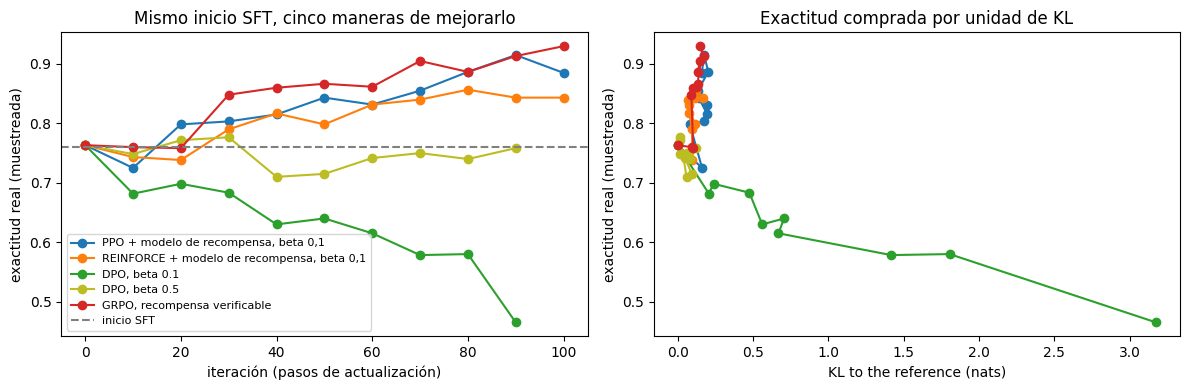

método                                 exact. real     KL
base (preentrenado)                        36.7% 
tras SFT                                   76.1%   0.00
PPO + modelo de recompensa, beta 0,1       88.5%   0.16
REINFORCE + modelo de recompensa, beta 0,1     84.3%   0.12
DPO, beta 0.1                              46.5%   3.18
DPO, beta 0.5                              75.8%   0.12
GRPO, recompensa verificable               93.0%   0.15
PPO, beta 0 (sobreoptimizado)              18.7%   5.18

tiempo total del notebook: 660 s


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
curves = [("PPO + modelo de recompensa, beta 0,1", runs["ppo"][1], "tab:blue"), ("REINFORCE + modelo de recompensa, beta 0,1", runs["reinforce"][1], "tab:orange"),
          ("DPO, beta 0.1", dpo[0.1][1], "tab:green"), ("DPO, beta 0.5", dpo[0.5][1], "tab:olive"), ("GRPO, recompensa verificable", grpo[1], "tab:red")]
for lab, h, c in curves:
    ax[0].plot(h[:, 0], h[:, 1], "o-", color=c, label=lab); ax[1].plot(h[:, 3], h[:, 1], "o-", color=c, label=lab)
ax[0].axhline(acc_sft_s, color="gray", ls="--", label="inicio SFT"); ax[0].set_xlabel("iteración (pasos de actualización)"); ax[0].set_ylabel("exactitud real (muestreada)"); ax[0].set_title("Mismo inicio SFT, cinco maneras de mejorarlo")
ax[1].set_xlabel("KL to the reference (nats)"); ax[1].set_ylabel("exactitud real (muestreada)"); ax[1].set_title("Exactitud comprada por unidad de KL"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
rows = [("base (preentrenado)", acc_base_s, None), ("tras SFT", acc_sft_s, 0.0)] + [(lab, h[-1, 1], h[-1, 3]) for lab, h, c in curves] + [("PPO, beta 0 (sobreoptimizado)", over[0.0][1][-1, 1], over[0.0][1][-1, 3])]
print(f"{'método':38s} {'exact. real':>9s} {'KL':>6s}")
for lab, a, k in rows: print(f"{lab:38s} {a:9.1%} {'' if k is None else format(k, '6.2f')}")
print(f"\ntiempo total del notebook: {time.time() - T_START:.0f} s")

**Lectura.** GRPO con la recompensa verificable es la mejor ejecución de este notebook: la exactitud muestreada pasa del 76 % al 93 % en 100 iteraciones con una KL de solo 0,15, y no tiene un modelo de recompensa que se pueda explotar. La vía del modelo de recompensa con $\beta = 0{,}1$ llega al 88 % (92 % en la ejecución más larga de la sección 5, que además tuvo 50 iteraciones más), así que la diferencia entre ambas es del orden del ruido y del número de iteraciones y no afirmamos que GRPO sea mejor en general; lo que muestra el resultado es que **una recompensa comprobable da una señal limpia sin coste de modelado**. El precio es que necesita una tarea con verificador, por eso las recompensas verificables se usan para matemáticas y código y mucho menos para la utilidad en conversaciones abiertas. Obsérvese también que la ventaja normalizada por grupo elimina el desplazamiento de recompensa por prompt que nos perjudicó en la sección 4.

## 8. Comparación, límites, alineación y evaluación

La tabla de arriba pone cada etapa junto a las demás, todas partiendo del mismo modelo SFT (exactitud muestreada, una semilla, 600 prompts de evaluación). Límites honestos de este notebook:

* **Una semilla por ejecución y 600 a 1000 prompts de evaluación**: las diferencias de 2 a 3 puntos son ruido; el colapso por sobreoptimización (76 % a 19 %) y el fallo de DPO no lo son.
* **Un conjunto de preferencias generado por una regla**: las preferencias reales son subjetivas, inconsistentes entre anotadores y no pueden puntuarse contra una verdad. Aquí la regla nos deja ver la sobreoptimización; en la práctica se detecta de forma indirecta (evaluación humana con datos no vistos, otras métricas).
* **Escala diminuta**: 100 mil pesos, respuestas de 6 tokens, una sola habilidad. El post-entrenamiento de producción usa modelos de miles de millones de pesos, respuestas de cientos o miles de tokens, un modelo de recompensa de tamaño comparable, miles de anotadores (o un juez de IA guiado por principios escritos, como en la [IA constitucional](https://arxiv.org/abs/2212.08073)), una gran mezcla de prompts y muchas otras etapas (entrenamiento de seguridad, rechazos, uso de herramientas, comportamiento con contexto largo). La receta de [Ouyang et al. 2022](https://arxiv.org/abs/2203.02155) (SFT, modelo de recompensa, PPO con penalización KL) y su versión anterior para resúmenes ([Stiennon et al. 2020](https://arxiv.org/abs/2009.01325)) son las contrapartes reales de las secciones 2 a 4; [Christiano et al. 2017](https://arxiv.org/abs/1706.03741) introdujo el aprendizaje de una recompensa a partir de comparaciones humanas por pares.
* **Los hiperparámetros se ajustaron en esta tarea** (tasas de aprendizaje, $\beta$, la línea base); otra elección cambia números concretos, y durante el desarrollo una línea base con la media del lote y un coeficiente KL menor dieron ejecuciones con modelo de recompensa mucho peores, lo que ya recuerda lo sensible que es el RLHF (aprendizaje por refuerzo con retroalimentación humana).

**Alineación, seguridad y evaluación.** Lo que optimizamos aquí es un número que representa "bueno". La alineación es el problema de que ese número puede no representar lo que queremos decir, y la sección 5 es su forma más pequeña: cuanto más fuerte optimizamos un sustituto, más depende el resultado de los puntos ciegos del sustituto. Entre las preocupaciones reales están la manipulación de la recompensa que las personas no notan (una respuesta segura pero errónea bien valorada por un anotador), la adulación (dar la razón al usuario porque eso se premia), la pérdida de diversidad tras una optimización fuerte y el exceso de rechazos cuando domina la señal de seguridad. Por eso la evaluación debe ser **independiente de la señal de entrenamiento**: prompts no vistos, otro juez u otra métrica, comparaciones de salidas muestreadas por personas, red-teaming (intentos deliberados de romper el modelo) y seguimiento de la KL y de la longitud de las salidas durante el entrenamiento. El módulo 12 de Neural Networks 1002 (IA responsable) trata con más profundidad la evaluación de seguridad y equidad.

## Ideas clave

* Un modelo base aprende la *distribución* de su texto, errores incluidos; su respuesta voraz puede ser correcta aunque las muestreadas no lo sean (99,5 % voraz frente a 36,7 % muestreada aquí).
* **SFT** con pocas demostraciones correctas es barato y dio +39 puntos de exactitud muestreada; las etapas de preferencias y recompensa trabajan sobre lo que deja.
* Un **modelo de recompensa** entrenado con la pérdida de Bradley-Terry alcanzó cerca del 95 % de acierto por pares frente a la verdad, lo que es bueno y aun así explotable.
* El **gradiente de política con penalización KL** (REINFORCE o una actualización recortada tipo PPO, con línea base por prompt) mejoró la exactitud hasta los 80 altos o 90 bajos con una KL de unos 0,1 a 0,2 nats.
* **La sobreoptimización se puede medir**: sin ancla KL la recompensa sustituta siguió siendo la más alta mientras la exactitud real caía del 76 % al 19 %; el coeficiente KL la controla.
* **DPO** elimina el modelo de recompensa y el bucle de muestreo, pero en este juguete ruidoso y fuera de línea no ayudó; necesita cuidado, no es un sustituto gratuito.
* **GRPO** con recompensa verificable no necesita modelo de recompensa ni red de valor y dio el mejor resultado aquí (93 %), al precio de necesitar un verificador.
* Todo esto es una semilla en un juguete; confía en los efectos grandes, no en las diferencias pequeñas.

## Ejercicios

1. Pon la tasa de etiquetas invertidas de `make_pairs` en 0 y luego en 0,3. ¿Cómo cambian la exactitud del modelo de recompensa y la política sobreoptimizada?
2. Entrena el modelo de recompensa con pares sin casi aciertos (`hard=0`). ¿Hace trampa más rápido la política con $\beta = 0$? ¿Qué escribe?
3. Repite la sección 5 con tres semillas (cambia `seed` en `run_rl`) y da la media y el rango de la exactitud real final para cada $\beta$. ¿Es estable el orden de las tres ejecuciones regularizadas?
4. Vuelve a poner la media del lote como línea base en `run_rl` en lugar de la media por prompt. Mide lo que pasa y explícalo con el desplazamiento por prompt de la sección 4.
5. Haz que DPO funcione: prueba una tasa de aprendizaje de $10^{-5}$, 30 pasos y pares sin ruido. ¿Cuál de los tres cambios importa más?
6. En GRPO, cambia el tamaño del grupo a $G=2$ y a $G=32$ manteniendo fijo el número de respuestas generadas por iteración. ¿Cuándo un grupo no da gradiente y cómo se relaciona con la exactitud del modelo de partida?
7. Da a GRPO una recompensa parcial (la fracción de caracteres correctos) en lugar de la coincidencia exacta. ¿Ayuda o abre una nueva forma de hacer trampa?
8. Piensa en una tarea real tuya (un resumen, una consulta SQL, una respuesta de chat): ¿cuáles de los tipos de recompensa de aquí (preferencia humana, modelo de recompensa aprendido, verificador) puedes construir y cómo detectarías la sobreoptimización?

## Referencias

* Christiano, P. F., Leike, J., Brown, T. B., Martic, M., Legg, S. and Amodei, D. (2017). Deep reinforcement learning from human preferences. NeurIPS. arXiv:1706.03741: https://arxiv.org/abs/1706.03741
* Stiennon, N. et al. (2020). Learning to summarize from human feedback. NeurIPS. arXiv:2009.01325: https://arxiv.org/abs/2009.01325
* Ouyang, L. et al. (2022). Training language models to follow instructions with human feedback. NeurIPS. arXiv:2203.02155: https://arxiv.org/abs/2203.02155
* Rafailov, R., Sharma, A., Mitchell, E., Ermon, S., Manning, C. D. and Finn, C. (2023). Direct preference optimization: your language model is secretly a reward model. NeurIPS. arXiv:2305.18290: https://arxiv.org/abs/2305.18290
* Shao, Z. et al. (2024). DeepSeekMath: pushing the limits of mathematical reasoning in open language models (introduces GRPO). arXiv:2402.03300: https://arxiv.org/abs/2402.03300
* Gao, L., Schulman, J. and Hilton, J. (2022). Scaling laws for reward model overoptimization. ICML 2023. arXiv:2210.10760: https://arxiv.org/abs/2210.10760
* Schulman, J., Wolski, F., Dhariwal, P., Radford, A. and Klimov, O. (2017). Proximal policy optimization algorithms. arXiv:1707.06347: https://arxiv.org/abs/1707.06347
* Ahmadian, A. et al. (2024). Back to basics: revisiting REINFORCE style optimization for learning from human feedback in LLMs. ACL 2024. arXiv:2402.14740: https://arxiv.org/abs/2402.14740
* Bai, Y. et al. (2022). Constitutional AI: harmlessness from AI feedback. arXiv:2212.08073: https://arxiv.org/abs/2212.08073
* Bradley, R. A. and Terry, M. E. (1952). Rank analysis of incomplete block designs: I. The method of paired comparisons. *Biometrika* 39, 324-345: https://doi.org/10.2307/2334029
* Williams, R. J. (1992). Simple statistical gradient-following algorithms for connectionist reinforcement learning (REINFORCE). *Machine Learning* 8, 229-256: https://doi.org/10.1007/BF00992696
* Schulman, J. (2020). Approximating KL divergence (blog note): http://joschu.net/blog/kl-approx.html